# 13. 运行图设计模式

## 13.1. 概述

**`LangGraph`** 官方总结了常用的状态图设计模式，如下：

| 模式                      | 图结构                    | 运行时动态性 | 核心 `LangGraph` 能力                         |
| ------------------------- | ------------------------- | ------------ | --------------------------------------------- |
| **`Prompt Chaining`**     | 顺序链                    | 低           | 静态边、条件边                                |
| **`Parallelization`**     | 固定 **`Fan-out/Fan-in`** | 低           | 并行超步、汇聚                                |
| **`Routing`**             | 条件分支                  | 中           | 结构化输出、条件边                            |
| **`Orchestrator-worker`** | 动态 **`Fan-out/Fan-in`** | 高           | **`Send`**、**`WorkerState`**、**`Reducer`**  |
| **`Evaluator-optimizer`** | 反馈循环                  | 中           | 条件边、循环、反馈状态                        |
| **`Agent`**               | 自主决策循环              | 最高         | **`MessagesState`**、工具调用、**`ToolNode`** |

## 13.2 实现
### 13.2.1 `Prompt Chaining`：提示词链
#### 13.2.1.1 核心思想
将一个复杂任务拆分成若干个顺序执行的小任务：

后一个节点依赖前一个节点的结果。

适合：

* 翻译 → 校对 → 润色
* 生成内容 → 检查一致性 → 修订
* 提取信息 → 分类 → 格式化
* 需求分析 → 生成代码 → 代码解释

可以存在条件边

#### 13.2.1.2 示例

In [14]:
import os
from typing import TypedDict
from langchain_deepseek import ChatDeepSeek
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
import sys
from loguru import logger
# 删除 Loguru 默认的 stderr sink
logger.remove()
# 重新添加支持颜色的 sink
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
DEEPER_API_KEY = os.environ["DEEPSEEK_API_KEY"]
DEEPSEEK_BASE_URL = os.environ["DEEPSEEK_BASE_URL"]  # 与本项目 .env 中的名称一致
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

# model = ChatOpenAI(
#     model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
#     api_key=OPENAI_API_KEY,
#     base_url=OPENAI_API_BASE,
# )
model = ChatDeepSeek(
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL"),
    model_name="deepseek-v4-flash",
    extra_body={"thinking": {"type": "disabled"}}
)

{
    'topic': '猫',
    'joke': 
'猫去面试，面试官问：“你有什么特长？”\n\n猫答：“我特别会抓重点。”\n\n面试官：“比如？”\n\n猫：“比如沙发重点。”',
    'improved_joke': 
'猫去面试，面试官问：“你有什么特长？”\n\n猫答：“我特别会**抓重点**。”\n\n面试官：“比如？”\n\n猫伸出爪子说：“比如沙
发的重点——**用爪一抓，重点就出来了**。”\n\n面试官：“那你还有别的特长吗？”\n\n猫：“当然，我还会**抓内涵**。”\n\n面试
官：“什么意思？”\n\n猫指着鱼缸：“里面的鱼，才是这份工作的**核心内容**。”',
    'final_joke': 
'猫去面试，面试官问：“你有什么特长？”\n\n猫答：“我特别会**抓重点**。”\n\n面试官：“比如？”\n\n猫伸出爪子说：“比如沙
发的重点——**用爪一抓，重点就出来了**。”\n\n面试官：“那你还有别的特长吗？”\n\n猫：“当然，我还会**抓内涵**。”\n\n面试
官：“什么意思？”\n\n猫指着鱼缸：“里面的鱼，才是这份工作的**核心内容**。”\n\n面试官沉默片刻，点头道：“很好，你被录用
了。”\n\n猫刚准备握手，面试官又补充：\n\n“不过这份工作的主要内容是——**抓猫**。”\n\n猫一愣：“抓我？”\n\n面试官推了推
眼镜：“对。我们公司是鱼缸保险公司，最近鱼总是被猫抓，老板让我们查出内鬼。”\n\n猫看了看鱼缸里的鱼，又看了看自己的爪
子：\n\n“那不用查了，**内鬼就在缸里——它刚才一直在给我使眼色。**”'
}

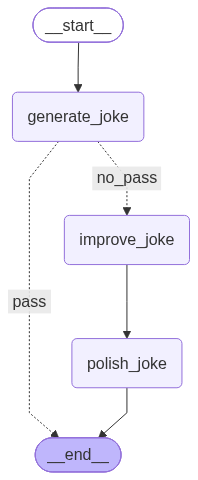

In [2]:
# 图状态
from typing import Literal


class OverAllState(TypedDict):
    topic: str
    joke: str
    improved_joke: str
    final_joke: str

# 节点
def generate_joke(state: OverAllState) -> OverAllState:
    """第一次调用大模型，生成初始笑话"""

    msg = model.invoke(
        [HumanMessage(content=f"写一个关于“{state['topic']}”的简短笑话")]
    )
    return {"joke": msg.content}

def check_punchline(state: OverAllState) -> Literal["pass", "no_pass"]:
    """判断笑话中是否包含包袱"""

    # 简单判断：笑话中是否包含问号或感叹号
    if "?" in state["joke"] or "!" in state["joke"]:
        return "pass"
    return "no_pass"

def improve_joke(state: OverAllState) -> OverAllState:
    """第二次调用大模型，通过添加双关语改进笑话"""

    msg = model.invoke(
        [HumanMessage(content=f"通过添加双关语，让下面这个笑话变得更有趣：\n{state['joke']}")]
    )
    return {"improved_joke": msg.content}

def polish_joke(state: OverAllState) -> OverAllState:
    """第三次调用大模型，对笑话进行最终润色"""

    msg = model.invoke(
        [HumanMessage(content=f"为下面这个笑话添加一个出人意料的反转：\n{state['improved_joke']}")]
    )
    return {"final_joke": msg.content}

# 构建工作流
builder = StateGraph(state_schema=OverAllState)

# 添加节点
builder.add_node("generate_joke", generate_joke)
builder.add_node("improve_joke", improve_joke)
builder.add_node("polish_joke", polish_joke)
# 添加边，连接各个节点
builder.add_edge(START, "generate_joke")
builder.add_conditional_edges(
    "generate_joke",
    check_punchline,
    {
        "no_pass": "improve_joke",
        "pass": END,
    },
)
builder.add_edge("improve_joke", "polish_joke")
builder.add_edge("polish_joke", END)

# 编译工作流
graph = builder.compile()

# 调用工作流
response = graph.invoke({"topic": "猫"})
from rich import print as rprint
rprint(response)

# 绘制拓扑结构
from IPython.display import display
display(graph)

### 13.2.2 `Parallelization`：并行化

#### 13.2.2.1. 核心思想
把相互独立的任务同时执行，最后汇总结果：

```text
                 ┌→ 任务 A ─┐
输入 → Fan-out ──┼→ 任务 B ─┼→ 聚合 → 输出
                 └→ 任务 C ─┘
```

官方将并行化分成两种用途：

1. **任务拆分**
   * 一个节点检查关键词
   * 一个节点检查格式
   * 一个节点检查事实准确性

2. **多次独立判断**
   * 多个模型或多个提示词分别评分
   * 最后投票、平均或综合判断

前者主要提升速度，后者主要提升置信度。

#### 13.2.2.2 示例

{
    'topic': '猫',
    'joke': '猫问主人：“你为什么总说我胖？”\n\n主人说：“因为你一坐下，沙发就叹气。”',
    'story': 
'雨停后，小猫团团发现屋檐下有一只迷路的小麻雀。它没有伸爪子，只轻轻喵了一声，陪小麻雀等到妈妈飞来。\n\n第二天，团团
窗台上多了一片亮晶晶的羽毛。它把羽毛藏进窝里，做了一个甜甜的梦。',
    'poem': ' 猫儿踏月上屋檐，  \n尾巴轻摇夜未眠。  \n一声喵落星河里，  \n悄悄守着小窗前。',
    'combined_output': 
'下面是一个关于“猫”的故事、笑话和诗歌！\n\n故事：\n雨停后，小猫团团发现屋檐下有一只迷路的小麻雀。它没有伸爪子，只轻
轻喵了一声，陪小麻雀等到妈妈飞来。\n\n第二天，团团窗台上多了一片亮晶晶的羽毛。它把羽毛藏进窝里，做了一个甜甜的梦。\
n\n笑话：\n猫问主人：“你为什么总说我胖？”\n\n主人说：“因为你一坐下，沙发就叹气。”\n\n诗歌：\n 猫儿踏月上屋檐，  
\n尾巴轻摇夜未眠。  \n一声喵落星河里，  \n悄悄守着小窗前。'
}

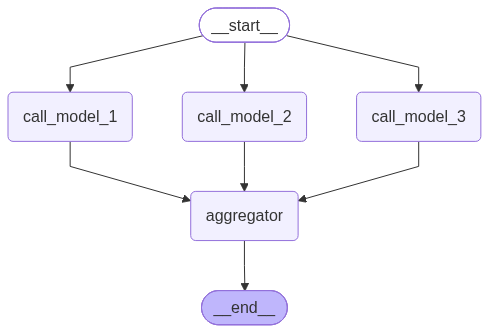

In [3]:
# 图状态
class OverAllState(TypedDict):
    topic: str
    joke: str
    story: str
    poem: str
    combined_output: str

# 节点
def call_model_1(state: OverAllState) -> OverAllState:
    """第一次调用大模型，生成笑话"""

    msg = model.invoke(
        [HumanMessage(content=f"写一个关于“{state['topic']}”的简短的笑话")]
    )
    return {"joke": msg.content}

def call_model_2(state: OverAllState) -> OverAllState:
    """第二次调用大模型，生成故事"""

    msg = model.invoke(
        [HumanMessage(content=f"写一个关于“{state['topic']}”的简短的故事")]
    )
    return {"story": msg.content}

def call_model_3(state: OverAllState) -> OverAllState:
    """第三次调用大模型，生成诗歌"""

    msg = model.invoke(
        [HumanMessage(content=f"写一首关于“{state['topic']}”的简短的诗")]
    )
    return {"poem": msg.content}

def aggregator(state: OverAllState) -> OverAllState:
    """将笑话、故事和诗歌合并为单一输出"""

    combined = f"下面是一个关于“{state['topic']}”的故事、笑话和诗歌！\n\n"
    combined += f"故事：\n{state['story']}\n\n"
    combined += f"笑话：\n{state['joke']}\n\n"
    combined += f"诗歌：\n{state['poem']}"
    return {"combined_output": combined}

# 构建工作流
builder = StateGraph(state_schema=OverAllState)

# 添加节点
builder.add_node("call_model_1", call_model_1)
builder.add_node("call_model_2", call_model_2)
builder.add_node("call_model_3", call_model_3)
builder.add_node("aggregator", aggregator)

# 添加边，连接各个节点
builder.add_edge(START, "call_model_1")
builder.add_edge(START, "call_model_2")
builder.add_edge(START, "call_model_3")
builder.add_edge(["call_model_1", "call_model_2", "call_model_3"], "aggregator")
builder.add_edge("aggregator", END)

graph = builder.compile()

# 调用工作流
response = graph.invoke({"topic": "猫"})
rprint(response)

from IPython.display import display
display(graph)

### 13.2.3 `Routing`：路由

#### 13.2.3.1 核心思想
先识别输入类型，再把请求送到专门的处理流程：

```text
                    ┌→ 退款流程
输入 → 路由判断节点 ─┼→ 售价咨询流程
                    └→ 商品推荐流程
```

它适合不同类型请求需要不同处理逻辑的场景，例如：

* 售前、售后、退款分类
* 普通问答、代码生成、数据分析
* 文本、图片、音频请求分类
* 不同领域知识库的选择

#### 13.2.3.2 设计原则

最佳实践：

* **`LLM` 节点**负责语义判断；
* **路由函数**负责把结构化结果映射到节点；
* **业务节点**负责真正处理任务。

不要让路由 LLM 直接返回任意节点名，否则模型输出和图结构会过度耦合，也难以进行类型检查和异常兜底。

#### 13.2.3.3 示例

猫为什么不喜欢上网？

因为它怕一不小心点了“喵”站。

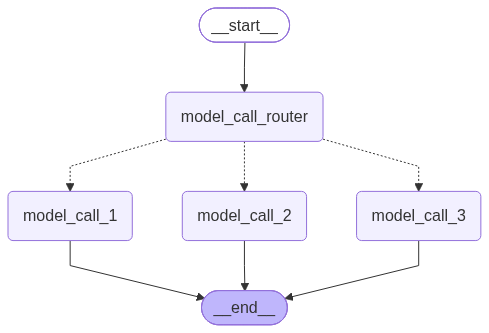

In [7]:
# 定义用于结构化输出的 Schema，作为路由判断依据

from pydantic import BaseModel, Field


class Route(BaseModel):
    step: Literal["poem", "story", "joke"] = Field(
        None,
        description="路由流程中的下一执行步骤",
    )

# 为大模型添加结构化输出能力
router = model.with_structured_output(Route)

# 图状态
class OverAllState(TypedDict):
    input: str
    decision: str
    output: str

# 节点
def model_call_1(state: OverAllState) -> OverAllState:
    """生成故事"""

    result = model.invoke(
        [HumanMessage(content=state["input"])]
    )
    return {"output": result.content}

def model_call_2(state: OverAllState) -> OverAllState:
    """生成笑话"""

    result = model.invoke(
        [HumanMessage(content=state["input"])]
    )
    return {"output": result.content}


def model_call_3(state: OverAllState) -> OverAllState:
    """生成诗歌"""

    result = model.invoke(
        [HumanMessage(content=state["input"])]
    )
    return {"output": result.content}

def model_call_router(state: OverAllState) -> OverAllState:
    """将用户输入路由到合适的节点"""

    # 调用具有结构化输出能力的大模型，完成路由判断
    decision = router.invoke(
        [
            SystemMessage(
                content=(
                    "根据用户的请求，将其路由到 story、joke 或 poem。"
                    "请求编写故事时返回 story，请求编写笑话时返回 joke，"
                    "请求编写诗歌时返回 poem。"
                )
            ),
            HumanMessage(content=state["input"]),
        ]
    )
    # 输出了Router 的类,包含step的属性
    return {"decision": decision.step}


# 条件边函数：根据路由决策选择下一个节点
def route_decision(
        state: OverAllState
) -> Literal[
    "model_call_1",
    "model_call_2",
    "model_call_3",
    END
]:
    # 返回接下来要执行的节点名称
    # 更新OverAllState的decision属性值
    if state["decision"] == "story":
        return "model_call_1"
    elif state["decision"] == "joke":
        return "model_call_2"
    elif state["decision"] == "poem":
        return "model_call_3"
    return END

# 构建工作流
builder = StateGraph(OverAllState)

# 添加节点
builder.add_node("model_call_1", model_call_1)
builder.add_node("model_call_2", model_call_2)
builder.add_node("model_call_3", model_call_3)
builder.add_node("model_call_router", model_call_router)

# 添加边，连接各个节点
builder.add_edge(START, "model_call_router")
builder.add_conditional_edges(
    "model_call_router",
    route_decision,
    {
        # route_decision 返回的名称：接下来要执行的节点名称
        "model_call_1": "model_call_1",
        "model_call_2": "model_call_2",
        "model_call_3": "model_call_3",
    },
)
builder.add_edge("model_call_1", END)
builder.add_edge("model_call_2", END)
builder.add_edge("model_call_3", END)

# 编译工作流
graph = builder.compile()
# 调用工作流
# 赋值了state 的 input 属性
state = graph.invoke({"input": "写一个关于猫的笑话"})
rprint(state["output"])

# 显示工作流图
from IPython.display import display
display(graph)

### 13.2.4 `Orchestrator-worker`：编排器—工作节点
#### 13.2.4.1 核心思想
编排器先分析任务，动态生成若干子任务，再创建对应数量的 Worker：

```text
                         ┌→ Worker 1 ─┐
输入 → Orchestrator ─────┼→ Worker 2 ─┼→ Synthesizer → 输出
                         ├→ Worker 3 ─┤
                         └→ Worker N ─┘
```

它通常包含三个组件：

| 组件                          | 职责                               |
| :---------------------------- | :--------------------------------- |
| **`Orchestrator`**（编排器）  | 分析任务、制定计划、生成子任务列表 |
| **`Workers`**（工作节点）     | 分别处理各子任务，通常并行执行     |
| **`Synthesizer`**（聚合节点） | 汇总所有 Worker 结果，生成最终答案 |

适合任务数量无法预先确定的场景，例如：

* 根据主题动态生成报告章节
* 修改未知数量的代码文件
* 为多个数据源分别执行分析
* 将长文档动态拆分为若干部分处理

#### 13.2.4.2 和`Parallelization`的区别
| 模式                      | 任务数量               |
| :------------------------ | :--------------------- |
| **`Parallelization`**     | 编译图时已确定（静态） |
| **`Orchestrator-worker`** | 运行时动态计算         |

#### 13.2.4.3 本质

**`Orchestrator-worker`** 本质上就是 **`Map-Reduce`**，我们在前面的课程中已经实现过了

```text
Orchestrator：生成 Map 任务
Send：动态分发
Worker：执行 Map
Reducer：合并中间结果
Synthesizer：执行 Reduce
```

#### 13.2.4.4. 示例

**示例如下**

{
    'topic': '撰写一份关于大语言模型缩放定律的报告',
    'sections': [
        Section(
            name='引言：从经验规律到工程指南',
            description="介绍缩放定律的背景与意义：为什么模型性能会随规模可预测地提升，缩放定律如何将深度学习从'炼
金术'推向可预测的工程学科。说明报告的范围、目标读者与结构安排，并点明核心问题——如何用有限算力获得最优性能。"
        ),
        Section(
            name='缩放定律的基本形式与数学框架',
            description='系统阐述缩放定律的幂律形式，包括Kaplan等人的早期公式与Chinchilla的修正形式。解释损失函数关
于参数量N、数据量D、计算量C的函数关系，讨论幂律指数、不可约损失项、样本效率与计算最优分配的数学推导。'
        ),
        Section(
            name='发展脉络：从Kaplan到Chinchilla及后续工作',
            description='梳理缩放定律的演进历史：Kaplan等（2020）提出参数优先的分配策略，Chinchilla（2022）指出数据
与参数应同比例扩展，以及后续关于数据受限、推理成本感知、超参数迁移等方向的修正与拓展研究。对比各阶段结论的差异与争
议来源。'
        ),
        Section(
            name='实证方法与实验设计',
            description='介绍拟合缩放定律的典型方法论：小规模模型扫描实验、学习率与批大小的超参数迁移、损失的可约与
不可约分解、拟合稳健性与外推有效性。讨论数据质量、分词器、架构差异对拟合结果的影响及常见陷阱。'
        ),
        Section(
            name='计算最优分配与实践启示',
            description='从缩放定律推导计算最优的参数量与数据量配比，讨论训练预算、推理预算的权衡，以及数据受限情形
下的策略调整。结合具体案例说明缩放定律如何指导模型规模决策、数据配比规划与训练计划制定。'
        ),
        Section(
            name='超越损失：下游能力、涌现与可预测性边界',
            description="讨论损失下降与下游任务表现之间的关系，辨析'涌现能力'争议与评测指标选择带来的假象。分析缩放
定律在哪些方面可靠、在哪些方面失效，包括数据质量、架构创新、后训练与强化学习对缩放曲线的影响。"
        ),
        Section(
            name='局限、批评与开放问题',
            description='讨论缩放定律的适用边界：数据墙与高质量数据枯竭、收益递减与经济成本、分布偏移与领域特化、拟
合外推的可信度、以及架构与算法创新是否会改写幂律。列出当前尚待解决的关键开放问题。'
        ),
        Section(
            name='结论与展望',
            description='总结缩放定律的核心结论与实践价值，展望多模态、推理时计算扩展、合成数据与数据高效学习等新方
向对缩放范式的重塑，给出面向研究与工程落地的建议。'
        )
    ],
    'completed_sections': [
        '# 引言：从经验规律到工程指南\n\n## 
缩放定律的背景与意义\n\n过去十年间，深度学习模型的参数规模从百万级跃升至万亿级，伴随着性能的持续提升。这一现象最初
被视为经验观察：更大的模型、更多的数据、更多的算力，往往带来更好的结果。然而，这种观察长期停留在"炼金术"式的试错层
面——研究者依赖直觉与反复试验来调整模型规模，缺乏可预测的理论框架。\n\n缩放定律（Scaling 
Laws）的出现改变了这一局面。它揭示了一个令人惊讶的事实：模型性能（通常以损失函数衡量）随模型参数量、训练数据量和计
算量的增加，呈现出高度可预测的幂律关系。这意味着，在投入大规模算力之前，研究者可以依据少量实验外推未来性能，从而将
模型开发从"事后解释"转变为"事前规划"。缩放定律因此成为连接经验观察与工程决策的桥梁，推动深度学习从一门依赖经验直觉
的学科，逐步走向可预测、可规划的工程学科。\n\n## 
报告范围与目标读者\n\n本报告聚焦缩放定律的核心结论及其工程转化路径。内容涵盖幂律关系的基本形式、计算最优分配策略、
不同规模区间下的实证发现，以及将这些规律落地为训练决策时的注意事项与边界条件。报告不追求对缩放定律文献的穷尽式综述
，而是以"如何用有限算力获得最优性能"这一核心问题为线索，组织相关知识与方法。\n\n目标读者为具备深度学习基础、正在或
即将参与大规模模型训练决策的研究者与工程师。读者无需预先熟悉缩放定律的具体公式，但应对模型训练的基本流程与常见指标
有所了解。\n\n## 
核心问题与结构安排\n\n贯穿全报告的核心问题是：**在给定算力预算下，如何分配模型规模与数据规模，才能获得最优性能？** 
这一问题直接决定了训练成本与最终效果之间的权衡，也是缩放定律最具工程价值的落点。\n\n报告结构如下：首先介绍缩放定律
的基本形式与实证基础，阐明性能随规模变化的幂律规律；随后讨论计算最优分配策略，回答算力约束下的规模配置问题；在此基
础上，梳理不同规模区间与任务设定下的实证发现与偏差；最后将上述规律整合为可操作的工程指南，并指出其适用边界与开放问
题。通过这一结构，报告试图完成从"经验规律"到"工程指南"的过渡，为有限算力下的模型训练决策提供系统参考。',
        '# 缩放定律的基本形式与数学框架\n\n## 1. 
幂律形式的基本表述\n\n缩放定律描述模型损失随规模变量（参数量、数据量、计算量）增长而按幂律下降的经验规律。其一般形
式可写为：\n\n$$L(x) = L_\\infty + A \\cdot x^{-\\alpha}$$\n\n其中 $x$ 为规模变量（$N$、$D$ 或 $C$），$L_\\infty$ 
为不可约损失项，$A$ 为比例常数，$\\alpha > 0$ 
为幂律指数。该形式意味着规模每增长一个数量级，损失按固定比例下降，且下降幅度随规模增大而递减，最终趋于不可约下界。\
n\n## 2. Kaplan 等人的早期公式\n\nKaplan 等人（2020）将损失分别建模为参数量 $N$ 与数据量 $D$ 的幂律函数：\n\n$$L(N)
= \\left(\\frac{N_c}{N}\\right)^{\\alpha_N}, \\quad L(D) = \\left(\\frac{D_c}{D}\\right)^{\\alpha_D}$$\n\n其中 
$N_c$、$D_c$ 为特征规模常数，$\\alpha_N \\approx 0.076$、$\\alpha_D \\approx 
0.095$。当同时考虑两者时，采用可加组合形式：\n\n$$L(N, D) = 
\\left[\\left(\\frac{N_c}{N}\\right)^{\\frac{\\alpha_N}{\\alpha_D}} + 
\\frac{D_c}{D}\\right]^{\\alpha_D}$$\n\n在计算量约束 $C \\approx 6ND$ 下，Kaplan 等人求得计算最优分配为 $N \\propto
C^{0.73}$、$D \\propto 
C^{0.27}$，即建议将大部分新增算力投入模型参数扩张，而非数据扩张。该结论隐含了较大的参数量—数据量比例。\n\n## 3. 
Chinchilla 的修正形式\n\nHoffmann 等人（2022）指出 Kaplan 
公式在拟合与学习率调度上存在偏差，并提出修正的参数化形式：\n\n$$L(N, D) = E + \\frac{A}{N^{\\alpha}} + 
\\frac{B}{D^{\\beta}}$$\n\n其中 $E$ 为不可约损失，$A, B$ 为常数，$\\alpha \\approx 0.34$、$\\beta \\approx 
0.28$（Chinchilla 拟合值）。与 Kaplan 
形式的关键差异在于：参数量项与数据量项以独立可加方式进入损失，且指数显著更大，意味着损失对规模更敏感。\n\n## 4. 
计算最优分配的数学推导\n\n在计算预算约束 $C = 6ND$ 下最小化 $L(N, D)$，构造拉格朗日函数：\n\n$$\\mathcal{L} = E + 
\\frac{A}{N^{\\alpha}} + \\frac{B}{D^{\\beta}} + \\lambda(6ND - C)$$\n\n对 $N$、$D$ 
求偏导并令其为零：\n\n$$\\frac{\\partial \\mathcal{L}}{\\partial N} = -\\alpha A N^{-\\alpha-1} + 6\\lambda D = 
0$$\n\n$$\\frac{\\partial \\mathcal{L}}{\\partia

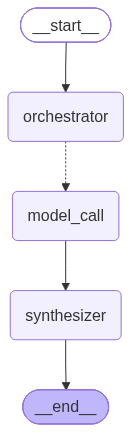

In [15]:
# 结构化输出的 Schema
from operator import add
from typing import Annotated, List, Sequence
from langgraph.types import Send


class Section(BaseModel):
    name: str = Field(
        description="报告的章节名称",
    )
    description: str = Field(
        description="本节主题和核心思想的概述",
    )

class Sections(BaseModel):
    sections: List[Section] = Field(
        description="报告的章节列表",
    )

# 编排器
planner = model.with_structured_output(Sections)
# 图状态
class OverAllState(TypedDict):
    topic: str  # 报告主题
    sections: list[Section]  # 报告章节列表
    completed_sections: Annotated[
        list, add
    ]  # 所有工作节点并行写入该字段
    final_report: str  # 最终报告


# 工作节点状态
class WorkerState(TypedDict):
    section: Section
    completed_sections: Annotated[list, add]

# 节点
def orchestrator(state: OverAllState) -> OverAllState:
    """编排器：生成报告编写计划"""

    # 生成报告章节规划
    report_sections = planner.invoke(
        [
            SystemMessage(content="为这份报告生成一个章节规划。"),
            HumanMessage(content=f"报告主题如下：{state['topic']}"),
        ]
    )

    return {"sections": report_sections.sections}


def model_call(state: WorkerState) -> WorkerState:
    """工作节点：编写报告中的一个章节"""

    # 生成章节内容
    section = model.invoke(
        [
            SystemMessage(
                content=(
                    "根据提供的章节名称和章节描述编写报告内容。"
                    "不要在每个章节前添加额外的开场说明。"
                    "使用 Markdown 格式。"
                )
            ),
            HumanMessage(
                content=(
                    f"章节名称：{state['section'].name}\n"
                    f"章节描述：{state['section'].description}"
                )
            ),
        ]
    )

    # 将生成的章节写入已完成章节列表
    return {"completed_sections": [section.content]}

# 条件边函数：为规划中的每个章节创建一个 model_call 工作节点
def assign_workers(state: OverAllState) -> Sequence[Send]:
    """为规划中的每个章节分配一个工作节点"""

    # 使用 Send API 并行启动各个章节的编写任务
    return [Send("model_call", {"section": s}) for s in state["sections"]]

def synthesizer(state: OverAllState) -> OverAllState:
    """将所有章节合成为完整报告"""

    # 获取所有已完成的章节
    completed_sections = state["completed_sections"]

    # 将已完成章节拼接为最终报告
    completed_report_sections = "\n\n---\n\n".join(completed_sections)

    return {"final_report": completed_report_sections}



# 构建工作流
builder = StateGraph(state_schema=OverAllState)

# 添加节点
builder.add_node("orchestrator", orchestrator)
builder.add_node("model_call", model_call)
builder.add_node("synthesizer", synthesizer)

# 添加边，连接各个节点
# 先设置编排器
builder.add_edge(START, "orchestrator")
builder.add_conditional_edges(
    "orchestrator",
    assign_workers,
    ["model_call"],
)
builder.add_edge("model_call", "synthesizer")
builder.add_edge("synthesizer", END)

# 编译工作流
graph = builder.compile()

# 调用工作流
state = graph.invoke(
    {"topic": "撰写一份关于大语言模型缩放定律的报告"}
)
rprint(state)
from IPython.display import Markdown, display

# 显示工作流图
display(graph)


In [16]:
# 渲染报告
Markdown(state["final_report"])

# 引言：从经验规律到工程指南

## 缩放定律的背景与意义

过去十年间，深度学习模型的参数规模从百万级跃升至万亿级，伴随着性能的持续提升。这一现象最初被视为经验观察：更大的模型、更多的数据、更多的算力，往往带来更好的结果。然而，这种观察长期停留在"炼金术"式的试错层面——研究者依赖直觉与反复试验来调整模型规模，缺乏可预测的理论框架。

缩放定律（Scaling Laws）的出现改变了这一局面。它揭示了一个令人惊讶的事实：模型性能（通常以损失函数衡量）随模型参数量、训练数据量和计算量的增加，呈现出高度可预测的幂律关系。这意味着，在投入大规模算力之前，研究者可以依据少量实验外推未来性能，从而将模型开发从"事后解释"转变为"事前规划"。缩放定律因此成为连接经验观察与工程决策的桥梁，推动深度学习从一门依赖经验直觉的学科，逐步走向可预测、可规划的工程学科。

## 报告范围与目标读者

本报告聚焦缩放定律的核心结论及其工程转化路径。内容涵盖幂律关系的基本形式、计算最优分配策略、不同规模区间下的实证发现，以及将这些规律落地为训练决策时的注意事项与边界条件。报告不追求对缩放定律文献的穷尽式综述，而是以"如何用有限算力获得最优性能"这一核心问题为线索，组织相关知识与方法。

目标读者为具备深度学习基础、正在或即将参与大规模模型训练决策的研究者与工程师。读者无需预先熟悉缩放定律的具体公式，但应对模型训练的基本流程与常见指标有所了解。

## 核心问题与结构安排

贯穿全报告的核心问题是：**在给定算力预算下，如何分配模型规模与数据规模，才能获得最优性能？** 这一问题直接决定了训练成本与最终效果之间的权衡，也是缩放定律最具工程价值的落点。

报告结构如下：首先介绍缩放定律的基本形式与实证基础，阐明性能随规模变化的幂律规律；随后讨论计算最优分配策略，回答算力约束下的规模配置问题；在此基础上，梳理不同规模区间与任务设定下的实证发现与偏差；最后将上述规律整合为可操作的工程指南，并指出其适用边界与开放问题。通过这一结构，报告试图完成从"经验规律"到"工程指南"的过渡，为有限算力下的模型训练决策提供系统参考。

---

# 缩放定律的基本形式与数学框架

## 1. 幂律形式的基本表述

缩放定律描述模型损失随规模变量（参数量、数据量、计算量）增长而按幂律下降的经验规律。其一般形式可写为：

$$L(x) = L_\infty + A \cdot x^{-\alpha}$$

其中 $x$ 为规模变量（$N$、$D$ 或 $C$），$L_\infty$ 为不可约损失项，$A$ 为比例常数，$\alpha > 0$ 为幂律指数。该形式意味着规模每增长一个数量级，损失按固定比例下降，且下降幅度随规模增大而递减，最终趋于不可约下界。

## 2. Kaplan 等人的早期公式

Kaplan 等人（2020）将损失分别建模为参数量 $N$ 与数据量 $D$ 的幂律函数：

$$L(N) = \left(\frac{N_c}{N}\right)^{\alpha_N}, \quad L(D) = \left(\frac{D_c}{D}\right)^{\alpha_D}$$

其中 $N_c$、$D_c$ 为特征规模常数，$\alpha_N \approx 0.076$、$\alpha_D \approx 0.095$。当同时考虑两者时，采用可加组合形式：

$$L(N, D) = \left[\left(\frac{N_c}{N}\right)^{\frac{\alpha_N}{\alpha_D}} + \frac{D_c}{D}\right]^{\alpha_D}$$

在计算量约束 $C \approx 6ND$ 下，Kaplan 等人求得计算最优分配为 $N \propto C^{0.73}$、$D \propto C^{0.27}$，即建议将大部分新增算力投入模型参数扩张，而非数据扩张。该结论隐含了较大的参数量—数据量比例。

## 3. Chinchilla 的修正形式

Hoffmann 等人（2022）指出 Kaplan 公式在拟合与学习率调度上存在偏差，并提出修正的参数化形式：

$$L(N, D) = E + \frac{A}{N^{\alpha}} + \frac{B}{D^{\beta}}$$

其中 $E$ 为不可约损失，$A, B$ 为常数，$\alpha \approx 0.34$、$\beta \approx 0.28$（Chinchilla 拟合值）。与 Kaplan 形式的关键差异在于：参数量项与数据量项以独立可加方式进入损失，且指数显著更大，意味着损失对规模更敏感。

## 4. 计算最优分配的数学推导

在计算预算约束 $C = 6ND$ 下最小化 $L(N, D)$，构造拉格朗日函数：

$$\mathcal{L} = E + \frac{A}{N^{\alpha}} + \frac{B}{D^{\beta}} + \lambda(6ND - C)$$

对 $N$、$D$ 求偏导并令其为零：

$$\frac{\partial \mathcal{L}}{\partial N} = -\alpha A N^{-\alpha-1} + 6\lambda D = 0$$

$$\frac{\partial \mathcal{L}}{\partial D} = -\beta B D^{-\beta-1} + 6\lambda N = 0$$

两式相除消去 $\lambda$，得到最优分配的必要条件：

$$\alpha A N^{-\alpha} = \beta B D^{-\beta}$$

即参数项与数据项对损失的边际贡献相等。由此解得：

$$N^* \propto C^{\frac{\beta}{\alpha+\beta}}, \quad D^* \propto C^{\frac{\alpha}{\alpha+\beta}}$$

代入 Chinchilla 拟合指数（$\alpha \approx 0.34$、$\beta \approx 0.28$），得 $N^* \propto C^{0.45}$、$D^* \propto C^{0.55}$，即参数量与数据量应近似等比例扩张。这与 Kaplan 的 $N \propto C^{0.73}$ 结论显著不同，Chinchilla 因此主张在给定算力下训练更小的模型、使用更多数据。

## 5. 样本效率与不可约损失的讨论

- **样本效率**：幂律指数 $\beta$ 反映损失对数据的敏感度。$\beta$ 越大，增加数据带来的损失下降越显著；在 Chinchilla 框架下，数据扩张的边际收益与参数扩张相近，故"数据受限"场景下应优先扩充高质量数据。
- **不可约损失 $E$**：代表数据分布本身的熵下界，无法通过扩大规模消除。$E$ 的估计直接影响外推预测的可靠性；若拟合区间未充分接近渐近区，$E$ 与指数估计可能产生偏差。
- **外推有效性**：幂律形式在小规模上拟合、在大规模上预测，其成立依赖于损失曲线在观测区间内保持单一幂律区制；学习率调度、架构变化等因素可能导致区制切换，破坏外推精度。

综上，缩放定律的数学框架以幂律加不可约项为核心，Kaplan 与 Chinchilla 的差异集中体现在函数参数化方式与由此导出的计算最优分配上，后者已成为当前规模决策的主要参考基准。

---

# 发展脉络：从Kaplan到Chinchilla及后续工作

## 一、Kaplan等（2020）：参数优先的分配策略

缩放定律的系统化研究始于Kaplan等（2020）的开创性工作。该研究通过拟合幂律关系，刻画了模型损失随参数量、数据量与计算量变化的规律，并据此提出了著名的分配建议：在固定计算预算下，应优先扩大模型参数量，而数据量的增长应相对缓慢。其核心经验规则是参数量随计算预算的增长速度快于数据量，且建议在训练充分收敛之前提前停止，以将节省的算力投入到更大的模型中。

这一结论奠定了"大模型优先"的早期范式，直接影响了GPT-3等后续模型的规模设计思路。然而，该结论依赖于特定的实验设置——固定的学习率调度、有限的训练token范围以及对训练不足模型的拟合方式，这些设定后来被证明对结论有实质性影响。

## 二、Chinchilla（2022）：数据与参数同比例扩展

Hoffmann等（2022）的Chinchilla工作对这一范式提出了直接挑战。通过在更广泛的模型规模与数据量组合上进行系统性训练并采用统一的训练调度，Chinchilla发现最优的参数量与数据量应大致同比例扩展，即每参数约需20个训练token。这意味着在相同计算预算下，先前的大模型应被显著缩小、同时用更多数据训练，从而获得更低的损失。

Chinchilla修正的实质在于：Kaplan等低估了数据的作用，其原因可归结为实验设计差异——包括学习率调度未随训练长度适配、对训练未充分模型的拟合偏差，以及不同规模下超参数未统一调优。Chinchilla的结论迅速成为新的经验基准，推动了一批"数据充分训练"的中等规模模型的出现。

## 三、后续修正与拓展方向

Chinchilla之后的研究从多个维度对原始结论进行了修正与拓展。

**数据受限情形。** 现实中高质量文本数据总量有限，无法无限同比例扩展。相关研究考察了在数据受限约束下的最优分配，指出当数据成为瓶颈时，应转向更大的模型并以多轮重复数据训练，此时重复数据的边际收益递减但并非为零，最优策略随数据约束的松紧程度而变化。

**推理成本感知。** 训练成本只是总成本的一部分。考虑部署阶段的推理开销后，最优模型往往比Chinchilla建议的更小、训练更充分，因为较小的模型推理成本更低，可通过延长训练来弥补性能。这一视角将缩放定律从纯训练预算优化扩展为全生命周期成本优化。

**超参数迁移。** 为使缩放定律在小规模实验上可靠地预测大规模行为，超参数随规模迁移的规律成为关键。研究提出随模型宽度与深度调整学习率、初始化方差等的迁移规则，减少了因超参数不匹配导致的预测偏差，也部分解释了早期不同研究结论的分歧。

## 四、各阶段结论的差异与争议来源

综观演进脉络，各阶段结论的差异主要源于三类因素：

1. **实验设计与拟合方法。** 训练调度是否随规模适配、是否包含训练不足的模型、拟合的函数形式与数据范围，均会系统性改变估计的指数与系数。Kaplan与Chinchilla的分歧很大程度上可归因于此。

2. **优化目标的不同。** 以训练损失最小化为目标（Chinchilla）与以全生命周期成本最小化为目标（推理成本感知研究）会给出不同的最优分配；数据受限研究则引入了额外的可行性约束。

3. **外推与迁移的可靠性。** 缩放定律本质上是经验拟合，其向更大规模的外推依赖于超参数迁移等假设的成立程度。假设不成立时，不同研究在小规模上的结论可能在大规模上失效或反转。

总体而言，该领域已从单一的"参数优先"经验规则，演变为在数据约束、成本结构与超参数迁移等多重条件下讨论最优分配的分层框架。Chinchilla确立了数据与参数平衡扩展的基准，而后续工作则表明，最优策略高度依赖于所设定的约束与目标，不存在脱离具体情境的普适分配方案。

---

## 实证方法与实验设计

拟合缩放定律的核心挑战在于：用有限算力的实验观测，推断更大规模下的损失行为。这一推断链条的可靠性完全取决于实验设计是否系统、测量是否可复现、外推是否经过验证。本章围绕拟合缩放定律的典型方法论展开，依次讨论小规模模型扫描实验的设计、超参数迁移策略、损失的可约与不可约分解、拟合稳健性与外推有效性，并分析数据质量、分词器与架构差异对拟合结果的影响及常见陷阱。

### 小规模模型扫描实验

拟合缩放定律的标准起点是一组小规模模型的扫描实验（sweep）。基本设计是在多个模型规模 \(N\)（参数量）与多个训练数据量 \(D\)（token 数）上构成网格，对每个 \((N, D)\) 组合训练并记录最终损失。关键设计决策包括：

- **规模跨度的选择**：模型规模应覆盖足够宽的范围（通常跨越 2–3 个数量级），且各规模点在对数尺度上近似等距分布。若规模点过于集中，幂律指数的估计方差会显著增大；若跨度过窄，外推距离过远，拟合的置信度难以保证。
- **计算预算的分配**：在固定总算力下，需在"多规模少数据点"与"少规模多数据点"之间权衡。前者有利于约束幂律指数，后者有利于约束数据项系数。实践中常采用多阶段设计：先以粗网格定位趋势，再在关键区域加密。
- **训练充分性**：每个 \((N, D)\) 点必须训练至损失收敛（或接近收敛），否则测得的损失混杂了优化不充分带来的误差。通常需监控训练损失曲线，并以学习率衰减后的终值作为测量值。
- **测量噪声控制**：同一配置的多随机种子运行可估计损失方差，用于加权拟合与不确定性传播。批次大小、序列长度、评估数据集的选取都应在整个扫描中保持一致。

### 学习率与批大小的超参数迁移

缩放定律描述的是"最优配置下"的损失，因此每个规模点都应使用该规模下的最优超参数。直接对每个 \((N, D)\) 组合做完整超参数搜索代价过高，标准做法是超参数迁移：在小规模上搜索最优学习率与批大小，再按经验规律外推到大规模。

具体而言，最优学习率随模型规模增大而减小（常近似为幂律或与宽度成反比），最优批大小随规模增大而增大（在临界批大小以下，增大批大小不损害样本效率）。迁移策略的有效性直接决定拟合质量：

- 若大规模点使用了非最优学习率，其损失会被系统性高估，导致拟合曲线在大规模端出现虚假的"弯曲"，进而扭曲指数估计；
- 批大小选择影响每步梯度噪声，进而影响收敛损失；临界批大小之外的增大不再改善损失，但会减少梯度更新步数，可能与学习率调度相互作用；
- 迁移规律本身需要在小规模上验证（例如在 2–3 个规模上检验迁移后超参数是否接近搜索得到的最优值），而非直接假设成立。

一个稳健的实践是对关键规模点做局部超参数微调，检验迁移超参数与搜索最优值之间的损失差距是否可忽略。

### 损失的可约与不可约分解

拟合缩放定律通常将损失分解为不可约项与可约项：

\[
L(N, D) = L_\infty + A N^{-\alpha} + B D^{-\beta}
\]

其中 \(L_\infty\) 为不可约损失（数据本身的熵下界，即无限模型与无限数据下的极限损失），\(A N^{-\alpha}\) 刻画模型容量不足带来的可约损失，\(B D^{-\beta}\) 刻画数据不足带来的可约损失。这一分解的实证意义在于：

- **\(L_\infty\) 的估计极其敏感**：它由外推得到，且与 \(\alpha, \beta\) 强相关。有限数据点上 \(L_\infty\) 的置信区间往往很宽，不同拟合方法给出的 \(L_\infty\) 可能相差可观。因此报告 \(L_\infty\) 时应同时报告不确定性，并避免在小跨度数据上过度解读。
- **可约项的分离**：在数据充足（\(D \to \infty\)）时损失随 \(N\) 的下降主要反映容量项，反之亦然。设计扫描时应包含"模型受限"与"数据受限"两个区域，否则两项系数难以同时辨识。
- **联合拟合与分步拟合**：可先固定数据量拟合约简形式估计 \(\alpha\)，再联合拟合全部参数。不同拟合顺序会引入不同的偏差，应作为敏感性分析的一部分报告。

### 拟合稳健性与外推有效性

拟合得到的缩放定律必须经过稳健性检验，才能用于外推预测。主要手段包括：

- **留出验证（hold-out）**：在扫描网格中留出部分规模点（尤其是最大规模点）不参与拟合，检验预测损失与实测损失的偏差。若最大规模点的预测误差显著大于小规模点，说明幂律形式在该区域失效或超参数迁移出现问题。
- **拟合方法敏感性**：比较对数空间最小二乘、加权最小二乘（按测量方差加权）、Huber 损失等不同目标函数下的参数估计。稳健的结论应在多种拟合方法下保持一致。
- **自助法（bootstrap）不确定性**：对数据点重采样估计参数分布，给出指数与 \(L_\infty\) 的置信区间，并据此评估外推预测的误差带。
- **外推距离的约束**：外推倍数（目标规模/最大拟合规模）应有限制。经验上，外推超过一个数量级时预测可靠性明显下降，需辅以中等规模点的验证。

外推有效性的一个常见误区是将"拟合优度高"等同于"外推可靠"。高 \(R^2\) 只说明拟合在观测范围内贴合，幂律形式在观测范围外的持续性需要独立证据。

### 数据质量、分词器与架构差异的影响

上述方法论假设测量的是同一"任务"上的损失。当数据、分词器或架构变化时，拟合结果的可比性受到挑战：

- **数据质量与分布**：不同质量的数据集具有不同的熵下界，因而 \(L_\infty\) 不同；数据去重、过滤策略变化会改变有效数据量，使 \(D\) 的名义计数失真。跨数据集比较缩放定律时，必须区分"数据量效应"与"数据分布效应"。
- **分词器**：不同分词器的词表大小与压缩率不同，同一文本对应的 token 数不同，导致 \(D\) 与损失（每 token 交叉熵）都不可直接比较。跨分词器比较需换算到共同单位（如每字节比特数），或固定分词器后再拟合。
- **架构差异**：Transformer 变体（不同归一化位置、激活函数、注意力变体）可能改变幂律指数或系数。混合专家模型的有效参数量与总参数量之别，也会使 \(N\) 的定义产生歧义。拟合时应明确 \(N\) 的度量口径，并在架构变化时重新验证而非直接套用旧定律。

### 常见陷阱

综合上述讨论，实证中高频出现的陷阱包括：

1. **训练不充分**：将未收敛的损失当作收敛损失，系统性高估可约项。
2. **超参数未迁移或迁移错误**：大规模点使用次优学习率/批大小，扭曲幂律形状。
3. **规模跨度过窄**：指数估计方差大，却报告为精确值。
4. **忽略测量噪声**：等权拟合使噪声大的点主导参数估计。
5. **过度解读 \(L_\infty\)**：将外推得到的不可约损失当作精确常数使用。
6. **混淆名义数据量与有效数据量**：重复数据、低质量数据使 \(D\) 的语义失真。
7. **跨分词器/架构直接比较**：未做单位换算即比较损失或指数。
8. **以拟合优度代替外推验证**：缺少留出点检验即宣称定律可外推。

严谨的实证应针对上述每一项给出明确的设计选择与检验结果，使缩放定律的参数估计附带可审计的误差来源说明。

---

# 计算最优分配与实践启示

## 一、从缩放定律推导计算最优配比

缩放定律揭示了模型损失与参数量 N、数据量 D 之间的幂律关系。以 Chinchilla 形式为例，损失可近似写为：

L(N, D) = E + A/N^α + B/D^β

其中 E 为不可约损失，A、B、α、β 为拟合常数。训练总计算量（FLOPs）近似为：

C ≈ 6ND

在固定计算预算 C 下，最小化 L(N, D) 即构成约束优化问题。对 N 与 D 分别求偏导并令其满足拉格朗日条件，可得计算最优的参数量与数据量满足：

N* ∝ C^(β/(α+β))，D* ∝ C^(α/(α+β))

Chinchilla 实证结果给出 α ≈ 0.34、β ≈ 0.28，对应 N* 与 D* 大致同比例增长，即每个参数约对应 20 个训练 token。这与早期"参数越大越好、数据相对不足"的做法形成鲜明对照：同等算力下，更小的模型配更多数据往往取得更低损失。后续研究（如对学习率调度、数据重复与多轮 epoch 的修正）对指数与比例有所调整，但"在算力约束下对 N 与 D 联合优化"这一方法论保持一致。

## 二、训练预算与推理预算的权衡

计算最优配比针对的是**训练**阶段的算力约束，但模型生命周期总成本还包括**推理**。推理成本与参数量近似成正比（每 token 前向 FLOPs ≈ 2N），因此存在两类取向：

- **训练最优（compute-optimal）**：在给定训练算力下追求最低损失，倾向较小模型、较多数据。
- **推理最优（inference-optimal）**：若模型将被大规模长期调用，则可在训练阶段"超额训练"小模型（数据量远超 20 token/参数），以略高的训练成本换取更低的单次推理成本。

实践中常用的决策框架是：将总预算视为训练成本与预期推理成本之和，对 N、D 联合优化总成本约束下的损失。当预期推理调用量很大时，最优解会向"更小 N、更大 D"偏移；反之，一次性或低频使用的模型更接近经典计算最优配比。这一权衡也解释了为何面向高并发服务的模型普遍采用较小规模但训练 token 数显著超过 Chinchilla 比例。

## 三、数据受限情形下的策略调整

当高质量数据总量不足以支撑计算最优的 D* 时，问题转为数据受限优化：固定 D = D_max，转而优化 N。此时最优参数量小于无约束情形，继续增大模型只会加剧过拟合式浪费。常见应对策略包括：

1. **多轮训练（multi-epoch）**：重复使用数据。前若干轮收益接近新数据，之后边际收益快速衰减，需按重复次数对有效数据量打折后重新求解最优 N。
2. **数据质量优先**：过滤、去重、配比调整可提升单位 token 的有效信息量，相当于在有限 D 下抬高 B/D^β 项的改善幅度。
3. **容量与数据匹配**：在数据受限时选择更小的 N 并配合更长的训练调度，避免"大模型饿数据"。
4. **合成数据与领域增补**：在质量可控前提下扩展数据池，但需评估分布偏移与重复放大风险。

## 四、案例：缩放定律指导规模决策与训练计划

**案例背景**：某团队拥有约 1×10^22 FLOPs 的训练预算，计划训练一个通用基础模型，并预期上线后有较大规模推理调用。

**步骤一：确定计算最优基线。** 由 C ≈ 6ND 与 Chinchilla 比例（D ≈ 20N）联立，解得 N ≈ sqrt(C/(6×20)) ≈ 9×10^9，D ≈ 1.8×10^11 token。即以约 90 亿参数、1.8 万亿 token 作为计算最优起点。

**步骤二：引入推理预算修正。** 由于推理调用量大，团队评估后决定将参数量下调至约 70 亿，同时把训练 token 提升至约 2.5 万亿（约 35 token/参数），属于轻度超额训练。按缩放定律估算，该配置训练损失略高于基线，但单 token 推理成本下降约 20%，在预期调用规模下总成本更优。

**步骤三：数据配比与可行性校验。** 团队盘点可用高质量 token 约 1.5 万亿，存在数据缺口。于是采取：多轮训练（核心语料最多 2 轮，按有效数据量折算）、加强去重与质量过滤、补充代码与多语数据。据此重新求解数据受限下的最优 N，将参数量定在约 60 亿至 70 亿区间，与步骤二结论一致。

**步骤四：训练计划制定。** 依据缩放定律外推不同规模下的损失曲线，用于设定中间检查点评估节点与早停判据；按 token 预算反推训练步数与学习率调度总长度；并以小规模代理实验校准 α、β 等常数，降低外推偏差。

**结果与启示**：最终模型规模小于"参数最大化"直觉下的选择，但在训练成本、推理成本与数据可得性三者间取得平衡。该案例表明，缩放定律的价值不在于给出唯一数字，而在于提供一套可复算的决策框架：先定预算与约束，再解最优配比，最后用数据与推理的实际条件做修正，并据此安排训练计划与评估节奏。

---

# 超越损失：下游能力、涌现与可预测性边界

## 损失下降与下游任务表现的关系

预训练损失是语言模型训练中最直接、最易监控的优化目标，但它与下游任务表现之间并非简单的单调映射。损失下降反映的是模型在训练分布上的平均似然改善，而下游能力取决于模型是否习得了任务所需的特定结构、推理模式或知识表征。二者在训练早期通常高度相关：损失快速下降的阶段往往伴随下游基准的同步提升。然而随着训练推进，这种相关性显著减弱，甚至出现分离。

分离的第一种表现是**损失持续下降而下游指标饱和**。当模型在预训练语料上已充分拟合常见模式后，进一步降低损失主要来自长尾分布与低频模式的拟合，这些改善未必转化为下游任务收益。第二种表现是**损失相近而下游表现差异显著**，这通常源于数据分布、数据质量、训练 curriculum 与后训练策略的差异。第三种表现更具迷惑性：**下游指标提升而损失几乎不变**，多见于指令微调、强化学习等后训练阶段——这些阶段改变的是模型输出的条件分布与行为策略，而非预训练似然。

因此，损失应被视为训练过程的**诊断信号**而非能力代理指标。将损失直接外推为下游能力预测，在方法论上存在系统性偏差。

## “涌现能力”争议与评测指标选择带来的假象

“涌现能力”指在小模型上不可见、随规模增大而突然出现的能力，这一概念自提出以来争议不断。核心质疑在于：许多被报告的“涌现”可能是**评测指标选择的产物**，而非模型能力的真实相变。

具体而言，当采用**不连续或阈值型指标**（如精确匹配准确率、多步推理全对率）时，模型输出从“部分正确”到“完全正确”的过渡在规模轴上会呈现陡峭跳跃。但若改用**连续型指标**（如 token 级对数似然、编辑距离、部分得分），同一组模型往往呈现平滑的、可外推的改进曲线。换言之，涌现的陡峭性部分来自指标的非线性变换，而非底层能力的不连续跃迁。

这一辨析的意义在于：它动摇了“能力不可预测”的强主张，但并未完全否定涌现。部分能力（如多步组合推理、上下文学习）在控制指标后仍表现出超线性改进，提示存在真实的规模阈值效应。当前共识倾向于：**涌现是真实存在的现象，但其显著程度被指标设计放大，且不同能力的涌现形态差异很大**。对实践者而言，关键含义是——报告涌现时必须同时报告指标选择与基线，避免将指标假象误读为能力相变。

## 缩放定律的可靠边界

缩放定律在特定条件下具有较强预测力：在**固定数据分布、固定架构族、固定训练配方**的前提下，损失随参数量、数据量与计算量的幂律关系在多个数量级上保持稳定，跨模型族的拟合误差可控。这使其成为训练预算分配与模型规模规划的有效工具。

但缩放定律的可靠性存在明确边界：

**数据质量方面**，幂律拟合假设数据分布恒定，而实际中数据去重、过滤、配比调整会改变有效数据分布，使损失曲线偏离原始外推。高质量数据可在更小规模上达到同等损失，等价于改变了缩放曲线的常数项；数据枯竭或质量下降则使曲线提前饱和。

**架构创新方面**，缩放定律的指数与常数依赖于架构族。注意力变体、混合专家、状态空间模型等结构性改变会重设曲线参数，跨架构外推失效。架构创新本质上是在改变“缩放的有效维度”，而非在既有曲线上滑动。

**后训练与强化学习方面**，缩放定律描述的是预训练似然，对后训练阶段的收益预测力有限。指令微调与 RLHF 改变的是输出分布与偏好对齐，其收益依赖基座模型能力、数据质量与算法设计，难以用预训练损失外推。强化学习尤其如此：RL 带来的能力提升可能呈现与预训练不同的规模依赖，甚至在基座能力不足时无法启动有效学习。

综上，缩放定律是**条件性工具**而非普适规律。其可靠区间是“固定配方内的规模外推”，失效区间是“配方变更、架构跃迁与后训练增益”。实践中应将其与下游评测、数据质量评估和后训练实验结合使用，并对超出拟合区间的外推保持审慎。

---

## 局限、批评与开放问题

缩放定律（Scaling Laws）虽然为大型模型的能力预测与资源分配提供了经验性框架，但其适用边界与内在局限同样值得系统审视。以下从五个维度讨论缩放定律面临的挑战，并列出当前尚待解决的关键开放问题。

### 数据墙与高质量数据枯竭

缩放定律通常以模型参数量、训练数据量和计算量为自变量刻画损失变化。然而，这一框架隐含假设高质量训练数据可以持续按比例扩展。现实情况是，公开可用高质量文本数据的增速已显著放缓，多模态数据虽在扩充，但清洗、标注与合规成本高企。当数据规模逼近可用上限时，单纯增加参数或计算的边际收益将受制于数据瓶颈，幂律外推的适用性随之削弱。数据重复使用、合成数据生成与数据质量筛选能否突破这一约束，仍是未决问题。

### 收益递减与经济成本

缩放定律所描述的幂律关系意味着损失随规模增长而持续下降，但下降速率递减。与此同时，训练与推理的经济成本随规模呈超线性增长。二者叠加导致“能力—成本”曲线的性价比在某一区间后显著恶化。缩放定律本身并不直接回答“何种规模下投入产出比最优”这一问题，且成本结构受硬件、能源、工程效率等多因素影响，难以纳入统一的幂律描述。经济可行性对缩放策略的约束，构成了对定律实用价值的实质性限制。

### 分布偏移与领域特化

缩放定律多在特定数据分布与评测集上拟合得到，其预测能力对分布内任务较为可靠，但在分布偏移情形下可信度下降。领域特化场景中，通用缩放曲线未必能准确刻画专业领域的能力演进；领域数据的稀缺性与异质性可能改变损失—规模关系的形状。跨分布外推时，幂律参数是否保持稳定、是否存在分布依赖的修正项，尚缺乏系统性证据。

### 拟合外推的可信度

缩放定律本质上是基于有限规模实验点的经验拟合。将其外推至远超观测范围的规模，隐含假设幂律形式在整个区间内保持不变。然而，训练过程中的相变现象、能力涌现以及优化不稳定等因素，可能导致损失曲线在特定规模处偏离幂律预测。拟合区间外的外推可信度缺乏理论保证，外推误差的量化与不确定性传播方法仍不完善。

### 架构与算法创新对幂律的改写

缩放定律的拟合通常固定架构族与训练方法。当出现显著架构创新（如注意力机制变体、混合专家结构）或算法改进（如优化器、数据课程、训练目标调整）时，损失—规模关系的系数乃至函数形式可能发生改变。这意味着缩放定律具有条件依赖性：它描述的是特定技术路径下的经验规律，而非普适不变量。创新是否会系统性改写幂律指数、是否存在跨架构的普适缩放形式，仍是开放议题。

### 关键开放问题

1. **数据受限条件下的缩放形式**：当高质量数据不可无限扩展时，损失随参数与计算的变化规律如何修正？数据重复与合成数据的有效缩放系数如何界定？
2. **幂律的普适性与条件依赖性**：是否存在跨架构、跨模态、跨训练目标的统一缩放形式？架构与算法创新在多大程度上改变幂律指数而非仅平移曲线？
3. **外推可信度的量化**：如何为缩放定律的外推预测提供误差界与置信区间？相变与涌现现象能否被纳入预测框架？
4. **分布偏移下的缩放校正**：领域特化与分布外推场景中，缩放曲线的偏差如何系统建模与校正？
5. **能力—成本联合优化**：如何将经济成本、推理开销与能力增益纳入统一的缩放决策框架，而非仅以训练损失为优化目标？
6. **缩放定律与下游任务表现的映射**：预训练损失与具体下游能力之间的缩放关系是否同样遵循幂律，其饱和点与失效条件如何刻画？

上述问题表明，缩放定律是有力的经验工具，但其边界条件、外推可靠性与技术路径依赖性决定了它尚不能作为能力预测的完备理论。对其局限的清醒认识，是合理运用该框架的前提。

---

## 结论与展望

### 核心结论与实践价值

缩放定律（Scaling Laws）揭示了模型性能与参数量、数据量、计算量之间稳定、可预测的幂律关系，其核心结论可归纳为三点：第一，性能提升在跨越多个数量级时呈现平滑可预测的规律，使大模型训练从"经验试错"转向"可规划的工程实践"；第二，存在计算最优分配原则，即在固定计算预算下，参数量与数据量应按特定比例协同扩展，避免单一维度过度投入导致的边际收益递减；第三，缩放定律为资源投入与预期收益之间建立了量化桥梁，使研发决策可在训练前进行成本-性能预判。

在实践价值层面，缩放定律已成为大模型研发的基础方法论：它支撑了训练预算的规划与算力配置、模型规模与数据配比的选型、以及早期性能的可靠外推与风险评估。对工程团队而言，它降低了大规模训练的不确定性；对研究社区而言，它提供了比较不同架构与训练策略的统一标尺。

### 新方向对缩放范式的重塑

**多模态扩展。** 随着模型从纯文本走向图文、音视频联合建模，缩放定律的适用边界正在扩展。多模态场景下，各模态的数据规模、信息密度与对齐质量差异显著，单一维度的幂律拟合难以刻画跨模态交互带来的非线性收益，"模态配比"本身成为新的可缩放变量，亟需建立多模态联合缩放的理论框架。

**推理时计算扩展。** 测试时计算（test-time compute）的引入改变了传统"训练即定型"的范式。通过思维链、采样搜索与验证机制，模型可在推理阶段以额外计算换取性能提升，形成"训练缩放"与"推理缩放"的双轴扩展空间。这要求重新界定计算最优的含义，并在训练成本与推理成本之间建立新的权衡模型。

**合成数据与数据高效学习。** 高质量真实数据正趋近枯竭，合成数据、数据筛选与课程学习成为延续缩放曲线的关键路径。但合成数据的收益存在饱和与分布偏移风险，数据质量的缩放规律尚不清晰。数据高效学习（如蒸馏、主动学习、数据重复策略）则试图在有限数据下逼近更大数据量的效果，可能改写"数据量-性能"的传统幂律形式。

上述方向共同指向一个趋势：缩放范式正从"单一维度的规模扩张"转向"多维度协同的精细化扩展"，定律的形式本身需要被重新参数化与验证。

### 面向研究与工程落地的建议

**研究层面：** 其一，建立多模态、推理时计算与数据质量维度的联合缩放理论，明确各维度的边际收益与交互效应；其二，加强合成数据与数据高效学习的可预测性研究，量化数据质量对缩放曲线的调制作用；其三，推动缩放定律在小规模可控实验中的可迁移性验证，降低外推风险。

**工程层面：** 其一，将缩放定律嵌入研发流程，形成"预算规划—规模选型—早期外推—风险预警"的闭环；其二，在训练与推理成本之间建立统一核算框架，按业务场景选择训练扩展或推理扩展的最优组合；其三，重视数据治理与合成数据质量评估体系建设，避免以量代质；其四，保持对小规模验证实验的持续投入，以低成本实验校准大规模外推的偏差。

总体而言，缩放定律已从描述性规律演进为可操作的工程准则，而多模态、推理时计算与数据高效学习等新方向正在拓展其适用边界。未来的关键在于将缩放范式从单轴扩张升级为多轴协同的可预测框架，使规模投入与性能收益之间的关系在更复杂的建模场景中依然可控、可解释、可复现。

### 13.2.5 `Evaluator-optimizer`：评估器—优化器
#### 13.2.5.1 核心思想

一个节点生成结果，另一个节点评估结果；不合格就携带反馈重新生成：

```text
          ┌──────────────────────┐
          ↓                      │
输入 → Generator → Evaluator ────┤
                      ├─ 不合格 ─┘
                      └─ 合格 → END
```

适合：

* 翻译质量迭代
* 代码生成与代码审查
* 文案生成与合规检查
* **`SQL`** 生成与语法验证
* 报告生成与事实检查
* 人工审批后修改

这种模式适用于存在明确质量标准，但通常需要多轮修改才能满足标准的任务。评估者既可以是 **`LLM`**，也可以是规则、测试程序或人类。

#### 13.2.5.2 必要的控制
为了避免无限循环，必须引入递归限制，可以是

- 优雅退出的主动方法
- 异常中断的被动方法

我们在介绍循环结构时已经系统讲解过了。

#### 13.2.5.3 示例

In [1]:
import os
from typing import TypedDict
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
import sys
from loguru import logger
# 删除 Loguru 默认的 stderr sink
logger.remove()
# 重新添加支持颜色的 sink
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

In [16]:
from pydantic import BaseModel, Field
from typing import Literal, TypedDict
# 图状态
class OverAllState(TypedDict):
    joke: str
    topic: str
    feedback: str
    funny_or_not: str

# 定义用于结构化输出的 Schema，作为笑话评估依据
class Feedback(BaseModel):
    grade: Literal["好笑", "不好笑"] = Field(
        description="判断这个笑话是否好笑。",
    )
    feedback: str = Field(
        description="如果笑话不好笑，请给出具体的改进建议。",
    )

# 为大模型添加结构化输出能力，定义评估器
evaluator = model.with_structured_output(Feedback)
count = 0 

# 节点
def model_call_generator(state: OverAllState) -> OverAllState:
    """大模型生成笑话"""
    global count     # 先声明使用模块级变量
    count += 1
    if state.get("feedback"):
        msg = model.invoke(
            f"""
            写一个关于“{state['topic']}”的笑话。

            请参考下面的改进建议：
            {state['feedback']}
            """
        )
    else:
        msg = model.invoke(f"写一个关于“{state['topic']}”的笑话")

    return {"joke": msg.content}


def model_call_evaluator(state: OverAllState) -> OverAllState:
    """大模型评估笑话"""

    grade = evaluator.invoke(
        f"""
        请评估下面这个笑话是否好笑：

        {state['joke']}
        """
    )

    return {
        "funny_or_not": grade.grade,
        "feedback": grade.feedback,
    }

# 条件边函数：根据评估结果决定结束流程，或者返回笑话生成节点
def route_joke(state: OverAllState) -> Literal["accept", "reject_and_feedback", END]:
    """根据评估结果决定接受笑话或根据反馈重新生成"""

    if state["funny_or_not"] == "好笑":
        return "accept"
    elif state["funny_or_not"] == "不好笑":
        return "reject_and_feedback"
    return END

# 构建工作流
builder = StateGraph(state_schema=OverAllState)

# 添加节点
builder.add_node("model_call_generator", model_call_generator)
builder.add_node("model_call_evaluator", model_call_evaluator)

# 添加边，连接各个节点
builder.add_edge(START, "model_call_generator")
builder.add_edge("model_call_generator", "model_call_evaluator")
builder.add_conditional_edges(
    "model_call_evaluator", route_joke,
    {
        "accept": END,
        "reject_and_feedback": "model_call_generator",
    }
)
# 编译工作流
graph = builder.compile()

In [17]:
from rich import print as rprint
# 调用工作流
state = graph.invoke({"topic": "猫"})
rprint(state["joke"])
rprint(count)

猫听说家里要装 Wi-Fi，高兴地守了一整天。主人问它在等什么，它说：“你不是说有鱼（Wi-Fi）吗？鱼呢？”

5

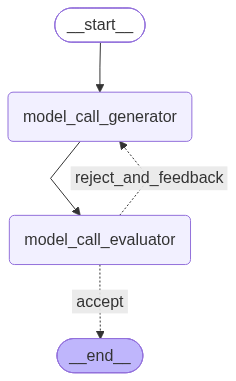

In [10]:
# 显示工作流图
from IPython.display import display
display(graph)

### 13.2.6 `Agent`：智能体循环

#### 13.2.6.1 核心思想

前面的运行图设计模式都属于 **`Workflow`**，**`Agent`** 与 **`Workflow`** 最大的不同是：

> 开发者不再预先确定每一步具体执行什么，而是让 **`LLM`** 根据当前消息和工具结果决定下一步行为。

基本拓扑是：

```text
          ┌─────────────────┐
          ↓                 │
输入 → LLM 决策 → 是否调用工具
                ├─ 是 → Tool ┘
                └─ 否 → END
```

即最基础的 **`ReAct`** 架构，我们已经不止一次介绍并实现过 **`ReAct`** 架构的 **`Agent`**

**`Agent`** 适合问题求解步骤和工具调用顺序无法预先确定的场景。开发者仍然负责提供工具集合、系统提示词、权限和边界，但具体执行过程由模型动态决定。

In [18]:
import os
from typing import TypedDict
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
import sys
from loguru import logger
# 删除 Loguru 默认的 stderr sink
logger.remove()
# 重新添加支持颜色的 sink
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

In [19]:
from langchain.tools import tool
from langgraph.prebuilt import ToolNode


@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    根据城市查询当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气不错"

tools = [get_weather]
model_with_tools = model.bind_tools(tools=tools)

def model_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    response = model_with_tools.invoke(input=messages)

    return {
        "messages": [response]
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    last_msg = state["messages"][-1]

    if last_msg.tool_calls:
        return "tool_node"
    return END

builder = StateGraph(state_schema=MessagesState)
builder.add_node("model_node", model_node)
builder.add_node("tool_node", ToolNode(tools=tools))

builder.add_edge(START, "model_node")
builder.add_conditional_edges("model_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "model_node")

graph = builder.compile()
response = graph.invoke({"messages": [HumanMessage(content="今天北京天气怎么样？")]})
rprint(response)

{
    'messages': [
        HumanMessage(
            content='今天北京天气怎么样？',
            additional_kwargs={},
            response_metadata={},
            id='7381fd4d-8096-4d3c-8f81-e6061a41e63c'
        ),
        AIMessage(
            content=[
                {
                    'id': 'rs_041f7616fd999cb2016ad8b28797a48199ae067bf8cc0f51fd',
                    'summary': [],
                    'type': 'reasoning',
                    'content': [],
                    'encrypted_content': 
'gAAAAABq2LKHkxksEdF6tdtFPlWQmX4pyyXvbNNaP_49wujqnlKc_mmLW5yWUhIo-KVg7vjQgtMomi70LOCY5Im-Ziqa6YhfcGwf7SaPr4mv9a2-3C
4cZ3LIgt-Q9GIPyVP4uNkS8jvgyQRnLm3neOa0owGFyygvq2xCSI6M8gd1tDV0XtwBXzG0-bVYpKuZ1_ntyM5a6IsU4mJ4Ct3kfgXYvBIxg2YdkCNbx
DRDf_IO3fnTYqJ3oLR5X-AGrQsGBaR3xlZYDnDv1SbGJh4fHFiM1_A5b7htLX5MKwO4d20n1ULbhtzUFP7r8l38xr_k0pUCUl-itUnUhBTmeAhXzZ1x
bgfX1_IhFj_KRCUwEXE0SCjTyScwDlbuMeHLYt3eRGiFexa9oYpjekGxfO8JgOy_QTNnYxfHhVDn1bJ90zB_sPE9vvKehbDvd7Y3gNZ79J3nqUZiatw
WkA-QM8yB8fHHx7aH0bi3vkcTPQhoVGHQIcLPoN49Yj6Keh7M0i8beIPEWpazbpk79HEKmaKqARl-RDns5XOHk_d7lYwfXPGUKgzM7mr-DllgsCBtqG
bTQmjKiL2Ozyctbs8Lu8WuWbHiHx7BGMAKoI9_3oPeTaqT-RDKz6GZmOgg67mUZVtHKV2oqvZxCvb5Ok-PniMX8Nt1vcDYY54do2wv6D-tTIjP74fqE
Yggk-QnhcQxgp_XZT8vOuc6dXqBYvl4yA4MEkZpsziqhXhhPkYbToS-DicvirORHGjSCq8ArmwBA0sC5yZIMm1HSd1Wll4sYSuA6KalcszTeT61JR31
fQlkyh4KKyS0dza60BvCRiD8AoYwIPws_XrAVd-CD4jBxb40RzI2GE1x3k5n24bzd8PCDb_gGzdtUJzguP3LSyCRKI8NdGMbjGQQouHwkUmOj2FzLUF
A4lPlKntjZpUBGmbxmN3MWn6pn157vuMiNMzLEYJYXR0EAqWFJRKEqbGfN8HkAUgS017ymy7wYEcalYSvtK9pQgD58F10Ici_PnVfU9g0tD4geDoRDz
JCpGn0nAsEhY7o5qzK2SoOV3Y1eq2gleAX-JxPuR51zwyn_OLveEss6YnxCHr5dCOhjA7soyJpL9o66HF5ELt4VIj_YfJBj15MhcAtCkf6jUITSS3dg
Qiv6OU7SGUkkzHXZiN2kFrcc0UvTSwja41UGoAco4nIXJGOkraVwdvqNniXsfGGx8UA1BaCbwInyR8NwBBLe4P7-6I2ChYlVtKhwQiD-CaHxJlPcg9V
GB05jGSvX4bOfXfKm_nkFSmLTs9xNjZk3g6SjfVk3Xa0tXwbCKT_U97WaGr0_1-Opwii34U679nT9MRkHbljdj4mZywfFuvDJa07zNClzha475NoIYF
RXHbkX1aTsR1mQMSGskh4RbwJbNmnv_HbJ-Cu-X_UBOaItwNAD3VUPotlL3zbvAkCFAQvnuc7L0vWdqD0c-lseaEErqvRP1zFDVuSb-ydVLne--Gr8v
547CQndkttPU3MfrImWJImbcLhUO5mq3NaHGf79fimB_JOy0b9Gv20aa11h0AMoVIwp0kixl4KRodjqGgTHCr1rfJuywSNsaBHBaloozigBSxlC2Sh2
f68m517ITNPdgcIT6534g1x3w==',
                    'metadata': {'turn_id': '01a15e79-5da8-7f1d-9eb6-36051646527d'},
                    'internal_chat_message_metadata_passthrough': {
                        'turn_id': '01a15e79-5da8-7f1d-9eb6-36051646527d'
                    }
                },
                {
                    'arguments': '{"city":"北京"}',
                    'call_id': 'call_ff9b920dea9b4b2b8ebca4a79d392cfc',
                    'name': 'get_weather',
                    'type': 'function_call',
                    'id': 'fc_041f7616fd999cb2016ad8b287b0088199911344ae4e389752',
                    'status': 'completed',
                    'metadata': {'turn_id': '01a15e79-5da8-7f1d-9eb6-36051646527d'},
                    'internal_chat_message_metadata_passthrough': {
                        'create_time': 1792586375.6887228,
                        'turn_id': '01a15e79-5da8-7f1d-9eb6-36051646527d'
                    }
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'resp_041f7616fd999cb2016ad8b286ff388199a74efb420af63a15',
                'created_at': 1792586375.0,
                'metadata': {},
                'model': 'gpt-6-sol',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-sol'
            },
            id='resp_041f7616fd999cb2016ad8b286ff388199a74efb420af63a15',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_ff9b920dea9b4b2b8ebca4a79d392cfc',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_

# 总结
### 1. LangGraph的设计模式
1. 直接 + 条件 都很简单
2. 编排器:
    - 编排器 负责每个工作节点的规划
    - 工作节点 实现规划
    - 汇总 所有工作节点连接到汇总点

3. 评估优化器:
    - 生成器: 负责做某件事,如果有评估结果,则根据评估结果以及建议生成
    - 评估器: 负责评估生成器的输出, 结构化输出 评估结果 以及 建议

4. Agent:
    - React架构： 根据是否需要调用工具节点
    